In [3]:
from baseline_functions import (
    prepare_data, describe_data, evaluate_model,
    show_strategy_metrics, show_final_comparison,
)

DATA_PATH = "classification_task1_train.xlsx"

data = prepare_data(DATA_PATH)   # {"df": dados brutos, "X": features, "y": HAB}
describe_data(data)

RESULTS = {}                     # (estratégia, modelo) -> resultados da validação

Linhas: 1063 | prevalência HAB: 0.130 | linhas completas: 563


#### Treino apenas com as linhas completas (sem CHL/CHL_uncertainty em falta):

### kNN (só linhas completas)

In [4]:
evaluate_model("kNN", "complete_only", data, RESULTS)

kNN  |  estratégia: complete_only


,val_year,n_train,n_val,n_pos_val,AUC,BalAcc,Accuracy,Recall,Precision,F1
0,2018,300,87,13,0.804,0.493,0.839,0.000,0.0,0.000
1,2019,387,89,17,0.733,0.500,0.809,0.000,0.0,0.000
2,2020,476,87,21,0.800,0.524,0.770,0.048,1.0,0.091


### Naive Bayes (só linhas completas)

In [5]:
evaluate_model("NaiveBayes", "complete_only", data, RESULTS)

NaiveBayes  |  estratégia: complete_only


,val_year,n_train,n_val,n_pos_val,AUC,BalAcc,Accuracy,Recall,Precision,F1
0,2018,300,87,13,0.815,0.507,0.161,1.0,0.151,0.263
1,2019,387,89,17,0.788,0.500,0.191,1.0,0.191,0.321
2,2020,476,87,21,0.791,0.500,0.241,1.0,0.241,0.389


### SVM (só linhas completas)

In [6]:
evaluate_model("SVM_RBF", "complete_only", data, RESULTS)

SVM_RBF  |  estratégia: complete_only


,val_year,n_train,n_val,n_pos_val,AUC,BalAcc,Accuracy,Recall,Precision,F1
0,2018,300,87,13,0.835,0.538,0.862,0.077,1.0,0.143
1,2019,387,89,17,0.779,0.529,0.820,0.059,1.0,0.111
2,2020,476,87,21,0.824,0.571,0.793,0.143,1.0,0.250


### Random Forest (só linhas completas)

In [7]:
evaluate_model("RandomForest", "complete_only", data, RESULTS)

RandomForest  |  estratégia: complete_only


,val_year,n_train,n_val,n_pos_val,AUC,BalAcc,Accuracy,Recall,Precision,F1
0,2018,300,87,13,0.902,0.627,0.851,0.308,0.5,0.381
1,2019,387,89,17,0.780,0.612,0.809,0.294,0.5,0.370
2,2020,476,87,21,0.812,0.646,0.759,0.429,0.5,0.462


### Regressão Logística (só linhas completas)

In [8]:
evaluate_model("LogReg", "complete_only", data, RESULTS)

LogReg  |  estratégia: complete_only


,val_year,n_train,n_val,n_pos_val,AUC,BalAcc,Accuracy,Recall,Precision,F1
0,2018,300,87,13,0.890,0.752,0.793,0.692,0.391,0.500
1,2019,387,89,17,0.804,0.681,0.775,0.529,0.429,0.474
2,2020,476,87,21,0.868,0.800,0.770,0.857,0.514,0.643


### Métricas dos métodos (só linhas completas)

Métricas agregadas - complete_only (anos [2018, 2019, 2020], limiar=0.5)


,AUC,PR_AUC,BalAcc,Accuracy,Recall,Precision,Specificity,F1,TP,FP,FN,TN
LogReg,0.850,0.521,0.752,0.779,0.706,0.456,0.797,0.554,36,43,15,169
RandomForest,0.832,0.543,0.634,0.806,0.353,0.500,0.915,0.414,18,18,33,194
SVM_RBF,0.818,0.550,0.549,0.825,0.098,1.000,1.000,0.179,5,0,46,212
NaiveBayes,0.799,0.513,0.502,0.198,1.000,0.195,0.005,0.326,51,211,0,1
kNN,0.786,0.445,0.507,0.806,0.020,0.500,0.995,0.038,1,1,50,211


AUC por ano de validação


val_year,2018,2019,2020,média,desvio
LogReg,0.890,0.804,0.868,0.854,0.045
RandomForest,0.902,0.780,0.812,0.831,0.063
SVM_RBF,0.835,0.779,0.824,0.812,0.030
NaiveBayes,0.815,0.788,0.791,0.798,0.015
kNN,0.804,0.733,0.800,0.779,0.040


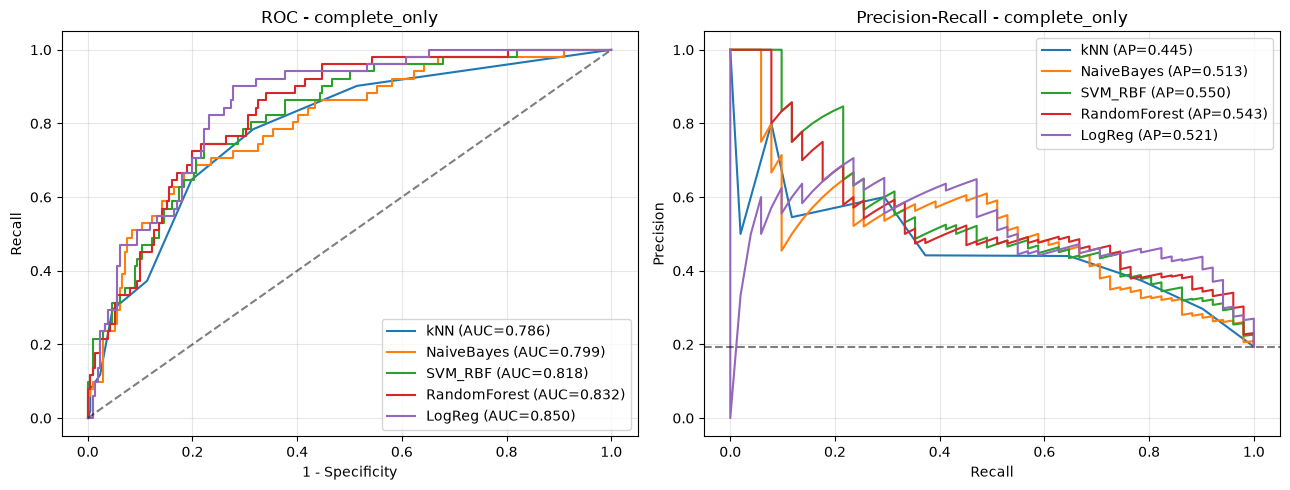

In [9]:
show_strategy_metrics("complete_only", RESULTS)





#### Treino com todas as linhas; CHL e CHL_uncertainty em falta são imputados com a mediana do treino de cada fold:

### kNN (mediana)

In [10]:
evaluate_model("kNN", "median_impute", data, RESULTS)

kNN  |  estratégia: median_impute


,val_year,n_train,n_val,n_pos_val,AUC,BalAcc,Accuracy,Recall,Precision,F1
0,2018,580,87,13,0.851,0.500,0.851,0.000,0.0,0.000
1,2019,742,89,17,0.709,0.500,0.809,0.000,0.0,0.000
2,2020,905,87,21,0.819,0.524,0.770,0.048,1.0,0.091


### Naive Bayes (mediana)

In [11]:
evaluate_model("NaiveBayes", "median_impute", data, RESULTS)

NaiveBayes  |  estratégia: median_impute


,val_year,n_train,n_val,n_pos_val,AUC,BalAcc,Accuracy,Recall,Precision,F1
0,2018,580,87,13,0.862,0.5,0.149,1.0,0.149,0.260
1,2019,742,89,17,0.779,0.5,0.191,1.0,0.191,0.321
2,2020,905,87,21,0.780,0.5,0.241,1.0,0.241,0.389


### SVM (mediana)

In [12]:
evaluate_model("SVM_RBF", "median_impute", data, RESULTS)

SVM_RBF  |  estratégia: median_impute


,val_year,n_train,n_val,n_pos_val,AUC,BalAcc,Accuracy,Recall,Precision,F1
0,2018,580,87,13,0.813,0.5,0.851,0.0,0.0,0.0
1,2019,742,89,17,0.806,0.5,0.809,0.0,0.0,0.0
2,2020,905,87,21,0.799,0.5,0.759,0.0,0.0,0.0


### Random Forest (mediana)

In [13]:
evaluate_model("RandomForest", "median_impute", data, RESULTS)

RandomForest  |  estratégia: median_impute


,val_year,n_train,n_val,n_pos_val,AUC,BalAcc,Accuracy,Recall,Precision,F1
0,2018,580,87,13,0.859,0.634,0.862,0.308,0.571,0.400
1,2019,742,89,17,0.766,0.604,0.831,0.235,0.667,0.348
2,2020,905,87,21,0.831,0.693,0.805,0.476,0.625,0.541


### Regressão Logística (mediana)

In [14]:
evaluate_model("LogReg", "median_impute", data, RESULTS)

LogReg  |  estratégia: median_impute


,val_year,n_train,n_val,n_pos_val,AUC,BalAcc,Accuracy,Recall,Precision,F1
0,2018,580,87,13,0.901,0.828,0.816,0.846,0.440,0.579
1,2019,742,89,17,0.805,0.683,0.742,0.588,0.385,0.465
2,2020,905,87,21,0.856,0.785,0.747,0.857,0.486,0.621


### Métricas dos métodos (mediana)

Métricas agregadas - median_impute (anos [2018, 2019, 2020], limiar=0.5)


,AUC,PR_AUC,BalAcc,Accuracy,Recall,Precision,Specificity,F1,TP,FP,FN,TN
LogReg,0.848,0.512,0.767,0.768,0.765,0.443,0.769,0.561,39,49,12,163
RandomForest,0.823,0.557,0.651,0.833,0.353,0.621,0.948,0.450,18,11,33,201
SVM_RBF,0.811,0.529,0.500,0.806,0.000,0.000,1.000,0.000,0,0,51,212
NaiveBayes,0.801,0.465,0.500,0.194,1.000,0.194,0.000,0.325,51,212,0,0
kNN,0.795,0.477,0.510,0.810,0.020,1.000,1.000,0.038,1,0,50,212


AUC por ano de validação


val_year,2018,2019,2020,média,desvio
LogReg,0.901,0.805,0.856,0.854,0.048
RandomForest,0.859,0.766,0.831,0.819,0.047
NaiveBayes,0.862,0.779,0.780,0.807,0.048
SVM_RBF,0.813,0.806,0.799,0.806,0.007
kNN,0.851,0.709,0.819,0.793,0.075


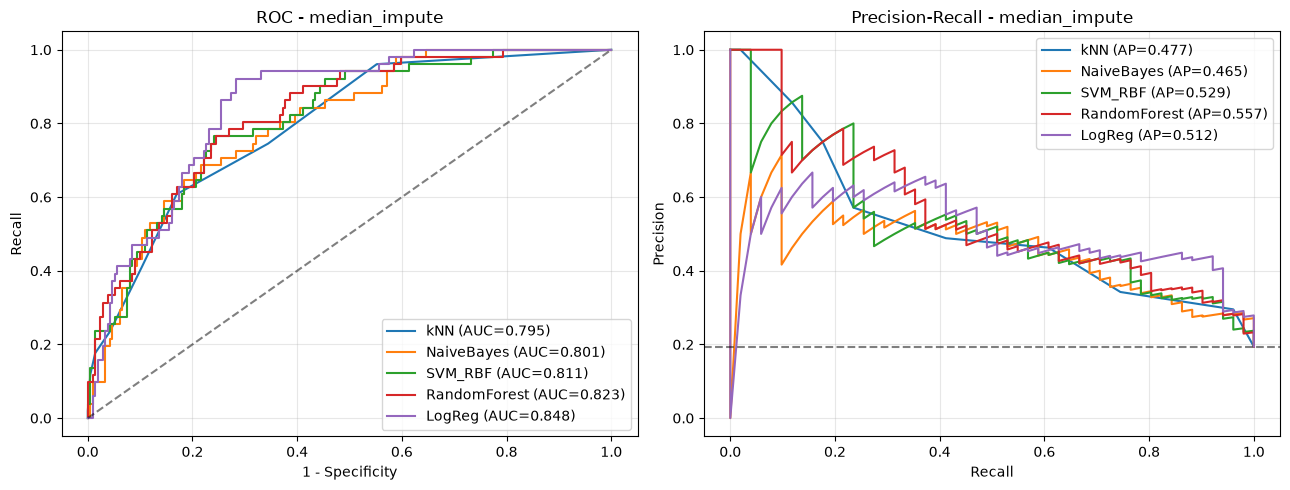

In [15]:
show_strategy_metrics("median_impute", RESULTS)

# Comparação final entre estratégias

AUC  PR_AUC  BalAcc  Accuracy  Recall  \
estratégia    modelo                                                  
complete_only LogReg        0.850   0.521   0.752     0.779   0.706   
median_impute LogReg        0.848   0.512   0.767     0.768   0.765   
complete_only RandomForest  0.832   0.543   0.634     0.806   0.353   
median_impute RandomForest  0.823   0.557   0.651     0.833   0.353   
complete_only SVM_RBF       0.818   0.550   0.549     0.825   0.098   
median_impute SVM_RBF       0.811   0.529   0.500     0.806   0.000   
              NaiveBayes    0.801   0.465   0.500     0.194   1.000   
complete_only NaiveBayes    0.799   0.513   0.502     0.198   1.000   
median_impute kNN           0.795   0.477   0.510     0.810   0.020   
complete_only kNN           0.786   0.445   0.507     0.806   0.020   

                            Precision  Specificity     F1  
estratégia    modelo                                       
complete_only LogReg            0.456        0.797  0.554  
median_impute LogReg            0.443        0.769  0.561  
complete_only RandomForest      0.500        0.915  0.414  
median_impute RandomForest      0.621        0.948  0.450  
complete_only SVM_RBF           1.000        1.000  0.179  
median_impute SVM_RBF           0.000        1.000  0.000  
              NaiveBayes        0.194        0.000  0.325  
complete_only NaiveBayes        0.195        0.005  0.326  
median_impute kNN               1.000        1.000  0.038  
complete_only kNN               0.500        0.995  0.038

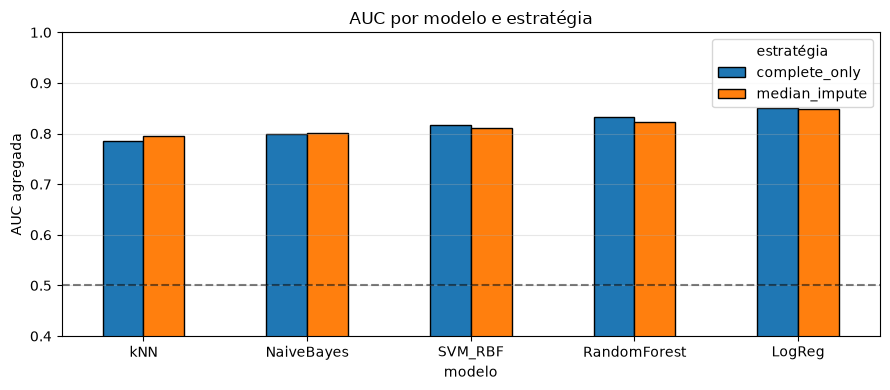

In [16]:
show_final_comparison(RESULTS)